# TP2 — Extraction d'information 

## Initialisation

In [2]:
import os
import random
from collections import Counter

import nltk
import pandas as pd
import spacy
import yake
from IPython.display import Image
from nltk.corpus import stopwords
from textblob import Blobber
from textblob_fr import PatternTagger, PatternAnalyzer
from wordcloud import WordCloud

nltk.download('stopwords', quiet=True)

year = 1945  # année choisie, entre 1887 et 1970
txt_path = "../../data/txt"  # tac/data/txt
out_path = "."  # les résultats (image, csv) sont écrits dans tps/tp2

## Fichiers retenus

Filtre sur le motif `_1945-` dans le nom du fichier, pour ne prendre que la date de publication.

In [5]:
files = sorted(f for f in os.listdir(txt_path) if f.endswith('.txt') and f"_{year}-" in f)
print(len(files), f"fichiers pour {year}")
files[:5]

100 fichiers pour 1945


['KB_JB838_1945-01-06_01-00004.txt',
 'KB_JB838_1945-01-13_01-00001.txt',
 'KB_JB838_1945-03-23_01-00002.txt',
 'KB_JB838_1945-04-02_01-00003.txt',
 'KB_JB838_1945-04-03_01-00002.txt']

## Mots-clés 

On garde les 50 mots-clés de chaque document, puis seuls les bigrammes alphabétiques. Le compteur indique le nombre de documents concernés, pas le nombre d'occurrences.

In [6]:
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_counter = Counter()

for f in files:
    text = open(os.path.join(txt_path, f), 'r', encoding='utf-8').read()
    keywords = kw_extractor.extract_keywords(text)
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2 and all(w.isalpha() for w in words):
            kw_counter[kw.lower()] += 1

kw_counter.most_common(20)

[('agence rossel', 35),
 ('rue royale', 17),
 ('bon état', 14),
 ('journal quotidien', 13),
 ('ecrire agence', 11),
 ('van acker', 11),
 ('soir illustré', 10),
 ('quotidien prix', 9),
 ('rue neuve', 6),
 ('rue van', 6),
 ('bruxelles dem', 6),
 ('prisonnier politique', 6),
 ('belle maison', 6),
 ('bonne maison', 6),
 ('vente publique', 6),
 ('affaires étrangères', 6),
 ('rendus rédaction', 5),
 ('bons gages', 5),
 ('question royale', 5),
 ('bruxelles demande', 5)]

## Nuage de mots

In [8]:
sw_base = stopwords.words("french")
sw_base += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
           "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
           "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
           "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
           "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]
sw_base = set(sw_base)

# Texte de toute l'année, lu une seule fois
year_text = ""
for f in files:
    year_text += open(os.path.join(txt_path, f), 'r', encoding='utf-8').read() + " "

def clean_words(text, stop):
    """Tokenise, garde les mots alphabétiques de plus de 2 lettres, hors stopwords"""
    words = nltk.wordpunct_tokenize(text)
    return [w.lower() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in stop]

# Tour 1 : stopwords de base
freq_1 = Counter(clean_words(year_text, sw_base))
freq_1.most_common(60)

[('rue', 3316),
 ('bruxelles', 1918),
 ('tél', 1731),
 ('ecr', 1536),
 ('ecrire', 1215),
 ('bon', 1035),
 ('maison', 1013),
 ('brux', 946),
 ('guerre', 891),
 ('ans', 888),
 ('prix', 855),
 ('agence', 752),
 ('place', 736),
 ('part', 708),
 ('grand', 620),
 ('état', 602),
 ('vend', 599),
 ('très', 597),
 ('belgique', 592),
 ('pays', 584),
 ('vendre', 576),
 ('demande', 575),
 ('lieu', 573),
 ('général', 568),
 ('ministre', 561),
 ('cherche', 555),
 ('gouvernement', 549),
 ('vente', 539),
 ('mod', 509),
 ('france', 498),
 ('prés', 497),
 ('belge', 481),
 ('cours', 464),
 ('trav', 459),
 ('etc', 459),
 ('lundi', 455),
 ('grande', 451),
 ('bonne', 445),
 ('soir', 444),
 ('leurs', 443),
 ('cour', 433),
 ('mardi', 431),
 ('serv', 431),
 ('heures', 426),
 ('travail', 421),
 ('mois', 419),
 ('app', 419),
 ('nord', 415),
 ('villa', 414),
 ('anvers', 411),
 ('mort', 405),
 ('avant', 404),
 ('dame', 397),
 ('pet', 395),
 ('louer', 394),
 ('toute', 391),
 ('bons', 389),
 ('président', 389),
 ('mi

### Tour 2 — bruit de l'OCR et vocabulaire publicitaire

Retirés : fragments tronqués (`ecr`, `adr`, `pet`), verbes et termes des annonces (`demande`, `prix`, `louer`, `achat`), et mots qui reviennent dans chaque annonce (`rue`, `agence`, `heures`).

In [9]:
JUNK2 = ['ecrire', 'ecr', 'adr', 'adresser', 'rue', 'avenue', 'agence', 'demande', 'prix', 'louer', 'vendre', 'vend', 'vente', 'cherche', 'bon', 'bons', 'bonne', 'bonnes', 'heures', 'midi', 'matin', 'soir', 'été', 'tél', 'quotidien', 'dame', 'villa', 'app', 'pet', 'ach', 'dactylo', 'ménage', 'mén', 'dés', 'fut', 'neuf', 'libre', 'gros', 'belle', 'etat', 'comm', 'conf', 'beau', 'bel', 'env', 'cap', 'pers', 'fin', 'appart', 'achat', 'porte']
sw_tour2 = sw_base | set(JUNK2)
freq_2 = Counter(clean_words(year_text, sw_tour2))
print(f"Tour 2 : {len(JUNK2)} mots ajoutés ; {len(freq_2)} formes différentes")
freq_2.most_common(60)

Tour 2 : 51 mots ajoutés ; 71914 formes différentes


[('bruxelles', 1918),
 ('maison', 1013),
 ('brux', 946),
 ('guerre', 891),
 ('ans', 888),
 ('place', 736),
 ('part', 708),
 ('grand', 620),
 ('état', 602),
 ('très', 597),
 ('belgique', 592),
 ('pays', 584),
 ('lieu', 573),
 ('général', 568),
 ('ministre', 561),
 ('gouvernement', 549),
 ('mod', 509),
 ('france', 498),
 ('prés', 497),
 ('belge', 481),
 ('cours', 464),
 ('trav', 459),
 ('etc', 459),
 ('lundi', 455),
 ('grande', 451),
 ('leurs', 443),
 ('cour', 433),
 ('mardi', 431),
 ('serv', 431),
 ('travail', 421),
 ('mois', 419),
 ('nord', 415),
 ('anvers', 411),
 ('mort', 405),
 ('avant', 404),
 ('toute', 391),
 ('président', 389),
 ('réf', 387),
 ('mercredi', 386),
 ('jeudi', 385),
 ('service', 374),
 ('août', 374),
 ('monsieur', 366),
 ('jour', 362),
 ('chef', 361),
 ('ordre', 360),
 ('politique', 355),
 ('temps', 353),
 ('juin', 350),
 ('samedi', 349),
 ('allemagne', 342),
 ('paris', 337),
 ('français', 334),
 ('uccle', 333),
 ('premier', 333),
 ('juillet', 332),
 ('centre', 331),

### Tour 3 — termes génériques, dates et abréviations

Retirés : mois et jours de la semaine, noms communs trop vagues (`part`, `place`, `cours`), et abréviations de l'OCR (`mme`, `trav`, `réf`).

In [10]:
JUNK3 = ['ans', 'mois', 'jour', 'jours', 'temps', 'part', 'partie', 'suite', 'place', 'lieu', 'grand', 'grande', 'cours', 'cour', 'ordre', 'lundi', 'mardi', 'mercredi', 'jeudi', 'vendredi', 'samedi', 'dimanche', 'janvier', 'février', 'mars', 'avril', 'mai', 'juin', 'juillet', 'août', 'septembre', 'octobre', 'novembre', 'décembre', 'état', 'travail', 'trav', 'serv', 'réf', 'référ', 'mod', 'prés', 'sér', 'fem', 'enf', 'mme', 'monsieur', 'rapp', 'faç', 'jne', 'sal', 'int', 'com', 'aven', 'cont', 'cherc', 'rem', 'mach', 'parf', 'gar', 'mat', 'bur', 'mol', 'off', 'jard', 'rez', 'soc']
sw_tour3 = sw_tour2 | set(JUNK3)
freq_3 = Counter(clean_words(year_text, sw_tour3))
print(f"Tour 3 : {len(JUNK3)} mots ajoutés ; {len(freq_3)} formes différentes")
freq_3.most_common(60)

Tour 3 : 67 mots ajoutés ; 71847 formes différentes


[('bruxelles', 1918),
 ('maison', 1013),
 ('brux', 946),
 ('guerre', 891),
 ('très', 597),
 ('belgique', 592),
 ('pays', 584),
 ('général', 568),
 ('ministre', 561),
 ('gouvernement', 549),
 ('france', 498),
 ('belge', 481),
 ('etc', 459),
 ('leurs', 443),
 ('nord', 415),
 ('anvers', 411),
 ('mort', 405),
 ('avant', 404),
 ('toute', 391),
 ('président', 389),
 ('service', 374),
 ('chef', 361),
 ('politique', 355),
 ('allemagne', 342),
 ('paris', 337),
 ('français', 334),
 ('uccle', 333),
 ('premier', 333),
 ('centre', 331),
 ('bureau', 329),
 ('allemands', 324),
 ('conseil', 312),
 ('radio', 308),
 ('ceux', 305),
 ('royale', 304),
 ('commerce', 296),
 ('jean', 296),
 ('firme', 294),
 ('vers', 292),
 ('francs', 288),
 ('belges', 287),
 ('roi', 286),
 ('londres', 281),
 ('peu', 280),
 ('situation', 280),
 ('armée', 280),
 ('louise', 279),
 ('anglais', 272),
 ('âge', 265),
 ('chambre', 262),
 ('etats', 262),
 ('salle', 260),
 ('quelques', 260),
 ('schaerbeek', 257),
 ('camp', 257),
 ('fem

### Tour 4 — mots grammaticaux absents de la liste NLTK

La liste NLTK installée ne contient pas `très`, `toute`, `peu`, `chez`, `déjà`. Ils sont retirés ici. La liste dépend de la version de NLTK : elle doit être vérifiée sur chaque machine.

In [11]:
JUNK4 = ['très', 'toute', 'toutes', 'peu', 'peut', 'chez', 'etc', 'déjà', 'avant', 'devant', 'vers', 'leurs', 'hui', 'fois', 'premier', 'première', 'car', 'puis', 'alors', 'quand', 'quelques', 'quelque', 'jamais', 'toujours', 'seul', 'seule', 'vue', 'dès', 'ceux', 'plusieurs', 'tant']
sw_tour4 = sw_tour3 | set(JUNK4)
freq_4 = Counter(clean_words(year_text, sw_tour4))
print(f"Tour 4 : {len(JUNK4)} mots ajoutés ; {len(freq_4)} formes différentes")
freq_4.most_common(60)

Tour 4 : 31 mots ajoutés ; 71818 formes différentes


[('bruxelles', 1918),
 ('maison', 1013),
 ('brux', 946),
 ('guerre', 891),
 ('belgique', 592),
 ('pays', 584),
 ('général', 568),
 ('ministre', 561),
 ('gouvernement', 549),
 ('france', 498),
 ('belge', 481),
 ('nord', 415),
 ('anvers', 411),
 ('mort', 405),
 ('président', 389),
 ('service', 374),
 ('chef', 361),
 ('politique', 355),
 ('allemagne', 342),
 ('paris', 337),
 ('français', 334),
 ('uccle', 333),
 ('centre', 331),
 ('bureau', 329),
 ('allemands', 324),
 ('conseil', 312),
 ('radio', 308),
 ('royale', 304),
 ('commerce', 296),
 ('jean', 296),
 ('firme', 294),
 ('francs', 288),
 ('belges', 287),
 ('roi', 286),
 ('londres', 281),
 ('situation', 280),
 ('armée', 280),
 ('louise', 279),
 ('anglais', 272),
 ('âge', 265),
 ('chambre', 262),
 ('etats', 262),
 ('salle', 260),
 ('schaerbeek', 257),
 ('camp', 257),
 ('femme', 257),
 ('ixelles', 255),
 ('fille', 252),
 ('hommes', 248),
 ('jardin', 245),
 ('jeune', 244),
 ('unis', 242),
 ('offre', 240),
 ('vie', 240),
 ('bourse', 239),
 (

### Enregistrement

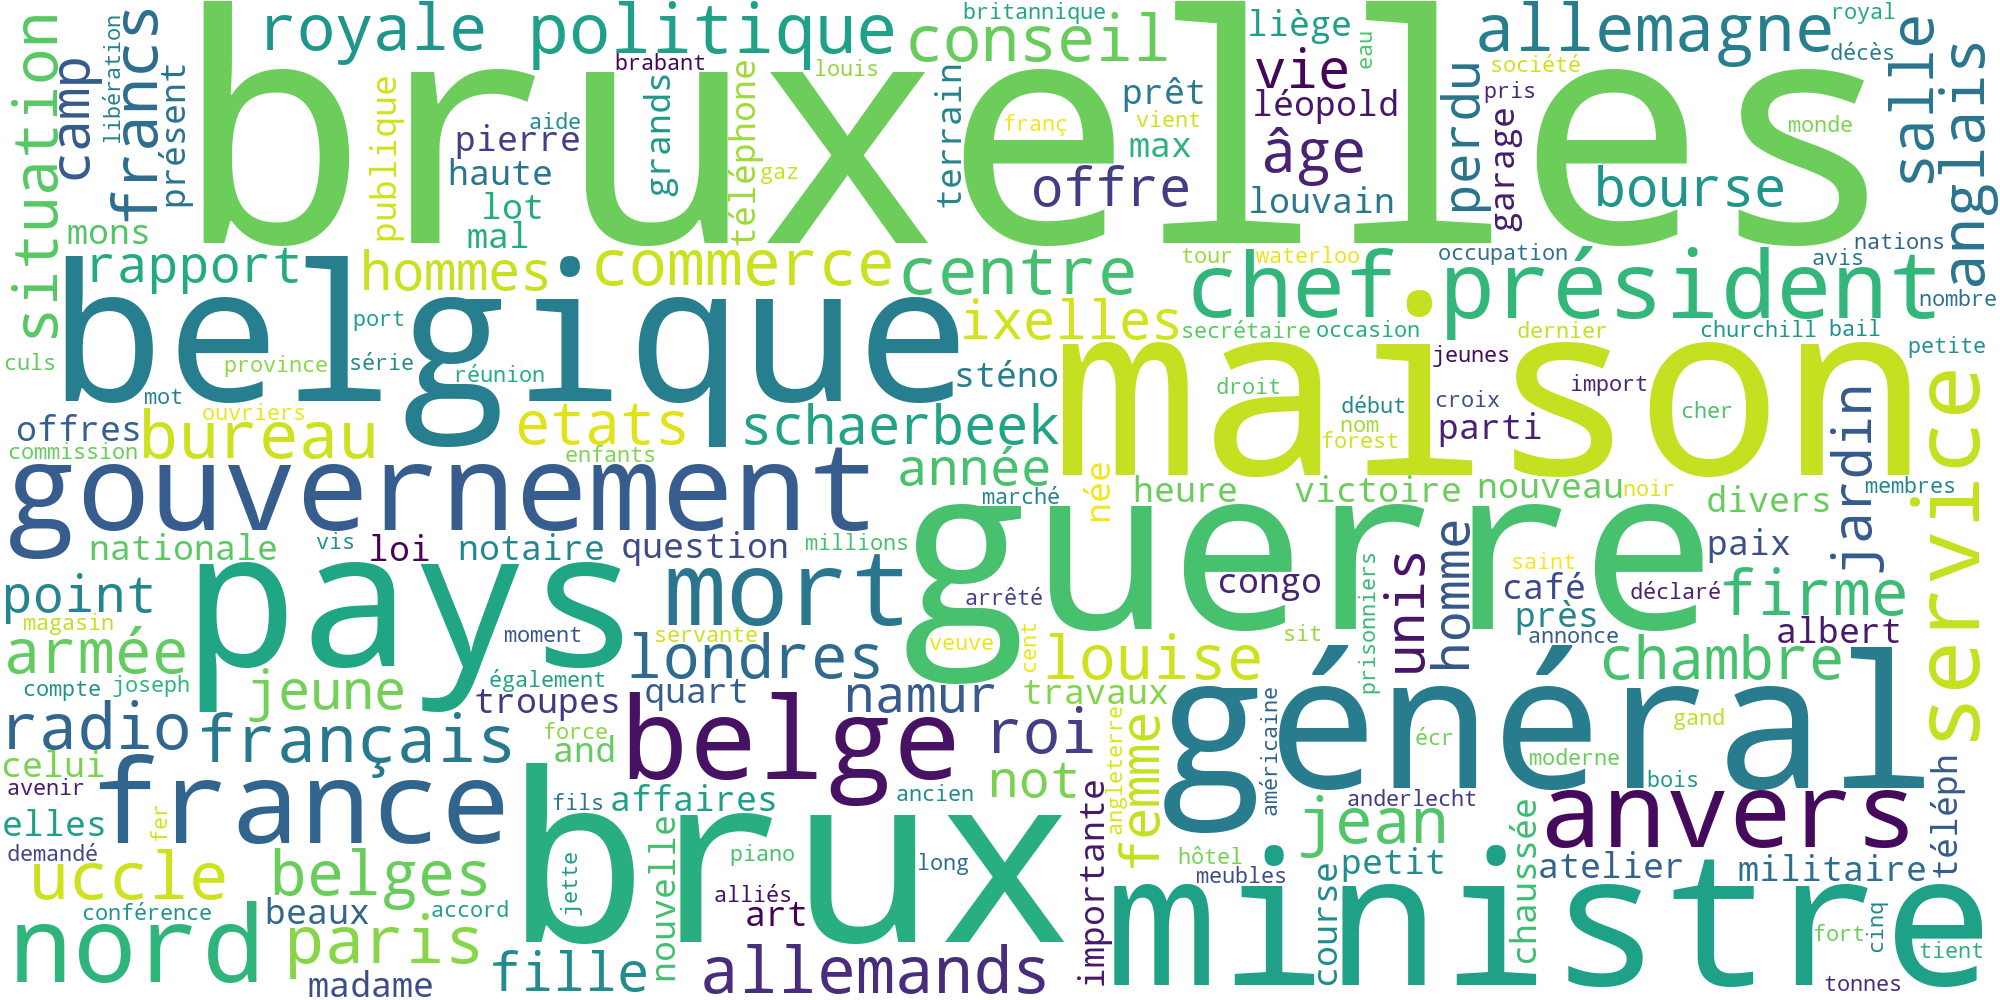

In [12]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(freq_4)
image_path = os.path.join(out_path, f"nuage_{year}.png")
cloud.to_file(image_path)
Image(filename=image_path)

## Entités nommées 

In [16]:
NER_EXCLUDE = set(['Rossel', 'Agence Rossel', 'Ecrire Ag', 'Rosse', 'g. Rossel', 'Rosseï', 'K ON DEM', 'K DEM', 'Téléphone', 'Téléph', 'Inst', 'Import', 'Monsieur', 'A. P.', 'A. F. P.', 'A.F.P.', 'Réun', 'AGENCE', 'FIRME', 'Etat', 'Référ'])
nlp = spacy.load('fr_core_news_md')
texts = [open(os.path.join(txt_path, f), 'r', encoding='utf-8').read() for f in files]

people, orgs, places = Counter(), Counter(), Counter()
for doc in nlp.pipe(texts, batch_size=4):
    for ent in doc.ents:
        name = " ".join(ent.text.split())
        if len(name) <= 3 or name.islower() or name in NER_EXCLUDE:
            continue
        if ent.label_ == "PER":
            people[name] += 1
        elif ent.label_ == "ORG":
            orgs[name] += 1
        elif ent.label_ == "LOC":
            places[name] += 1

print("Personnes :", people.most_common(15))
print("Organisations :", orgs.most_common(15))
print("Lieux :", places.most_common(15))

Personnes : [('Louise', 113), ('Hitler', 110), ('Laval', 86), ('M. Churchill', 75), ('Pétain', 69), ('général de Gaulle', 51), ('M. Van Acker', 50), ('Léopold', 47), ('Brugmann', 46), ('Rapp', 45), ('M. Spaak', 39), ('Jette', 36), ('Jardin', 36), ('Reine', 34), ('Hardy', 32)]
Organisations : [('Reuter', 133), ('Conseil', 104), ('Chambre', 85), ('GALERIES', 57), ('Parlement', 53), ('Gestapo', 51), ('Sénat', 42), ('Havas', 36), ('Ford', 34), ('Orchestre', 29), ('Justice', 28), ('Reich', 27), ('Citroën', 26), ('LEOPOLD', 26), ('ministre des Affaires étrangères', 25)]
Lieux : [('Bruxelles', 1270), ('Brux', 705), ('Belgique', 389), ('Allemagne', 309), ('Anvers', 238), ('Uccle', 225), ('Allemands', 210), ('Schaerbeek', 188), ('Londres', 177), ('Paris', 177), ('Etats-Unis', 161), ('Ixelles', 149), ('France', 148), ('Liège', 138), ('la France', 132)]


## Sentiment

Tirage de 10 phrases avec la graine `1945`. Filtres : majuscule en début de phrase, entre 8 et 40 mots.

In [17]:
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

candidates = []
for f in files:
    text = open(os.path.join(txt_path, f), 'r', encoding='utf-8').read()
    for sent in text.replace('\n', ' ').split('. '):
        sent = sent.strip()
        words = sent.split()
        n_words = len(words)
        if not sent or not sent[0].isupper() or not (8 <= n_words <= 40):
            continue
        clean_ratio = sum(len(w) > 2 and w.isalpha() for w in words) / n_words
        if clean_ratio >= 0.8:
            candidates.append((f, sent))

random.seed(year)
chosen = random.sample(candidates, 10)

rows = []
for f, sent in chosen:
    polarity, subjectivity = tb(sent).sentiment
    rows.append([f, sent, round(polarity, 2), round(subjectivity, 2)])

table = pd.DataFrame(rows, columns=['fichier', 'phrase', 'polarité', 'subjectivité'])
table.to_csv(os.path.join(out_path, f"sentiment_{year}.csv"), index=False)
table

,fichier,phrase,polarité,subjectivité
0,KB_JB838_1945-08-15_03-00001.txt,"Elle sera pour, nous toute parée des beautés o...",0.23,0.28
1,KB_JB838_1945-07-07_01-00001.txt,On doute que cette accusation ait impressionné...,0.10,0.10
2,KB_JB838_1945-06-22_01-00002.txt,Ce sont les ministres responsables qui seuls p...,0.10,0.30
3,KB_JB838_1945-12-30_02-00004.txt,NOËL NOUVEL ANj REVEILLONS LA COUPOLE PORTE 7 ...,0.43,0.48
4,KB_JB838_1945-10-14_01-00001.txt,"Son allégresse d’aujourd’hui, comporte quelque...",-0.20,0.25
5,KB_JB838_1945-12-24_02-00004.txt,Nous espéions entrer en relations étroites ave...,-0.10,0.10
6,KB_JB838_1945-07-07_01-00001.txt,Elle résidait plutôt dans la pénurie des matiè...,0.00,0.00
7,KB_JB838_1945-07-03_01-00002.txt,Il semble toutefois que le premier point soit ...,0.54,0.46
8,KB_JB838_1945-11-14_02-00002.txt,Pierlot avait annoncé que la guerre était fini...,0.00,0.00
9,KB_JB838_1945-12-09_01-00002.txt,J’ai déclaré alors clairement que nos troupes ...,0.04,0.15


## Lecture des scores

Polarité : de −1 (négatif) à +1 (positif). Subjectivité : de 0 (factuel) à 1 (opinion). L'interprétation se fait dans le rapport.

## Références

- YAKE : https://github.com/LIAAD/yake
- WordCloud : https://github.com/amueller/word_cloud
- spaCy : https://spacy.io/api
- TextBlob-FR : https://textblob.readthedocs.io/en/dev/